# Telco Customer Churn Prediction
# Group Members
| **Name**                   | **Registration Number** |
| -------------------------- | ----------------------- |
| Nakigudde Summayiyah       | 2025/DSMA/DAY/1499/G    |
| Ssempa Nelson              | 2025/DSMA/DAY/0476      |
| Bakyebirige Anthony Trevor | 2025/DSMA/DAY/1492/G    |



<a id="part-1"></a>
## Problem Identification
# Ideal Situation
The Ugandan National Development Plan IV (NDP IV), the Government Manifesto, and the UN Sustainable Development Goals (notably SDG 8 on decent work and economic growth, and SDG 9 on industry, innovation and infrastructure) all emphasise the importance of sustainable, digitally-driven service industries. In the telecommunications sector, the ideal situation is one of **high customer retention**, where:
- The majority of subscribers renew their contracts and remain with a provider over the long term.
- Service providers grow revenue predictably, invest in network quality, and lower customer acquisition costs.
- Consumer welfare improves through stable pricing, reliable service, and loyalty incentives.
In scholarly terms, the ideal state is captured by **Customer Lifetime Value (CLV)** frameworks, where long-tenure, low-churn customers generate most of a firm's profit (Gupta & Lehmann, 2005).
# The Problem
Customer churn — the phenomenon of subscribers discontinuing a service — is a persistent and costly problem in the telecommunications industry. In the Telco Customer Churn dataset, approximately **26.5% of customers churned**, meaning more than 1 in 4 subscribers left the provider.
# Who is Affected
- **The telecom provider** — loses recurring revenue and incurs high acquisition costs.
- **Shareholders and investors** — face reduced profitability.
- **Remaining customers** — may face price increases or reduced quality.
- **Employees** — downsizing often follows sustained churn.
# Why the Problem Matters
- **Direct revenue loss** — acquired customers are expensive; losing them wastes acquisition cost.
- **Reduced profitability** — retention is 5–25× cheaper than acquisition (Reichheld & Sasser, 1990).
- **Erosion of market share** — competitors gain share as customers switch.
- **Negative word-of-mouth** — churned customers rarely return.
- **Strategic planning difficulty** — unpredictable churn makes forecasting unreliable.
# Contributing Factors
- **Contract type** — month-to-month contracts have the highest churn.
- **Tenure** — newer customers churn more.
- **Pricing** — higher monthly charges correlate with churn.
- **Service quality** — fiber optic and lack of add-ons correlate with churn.
- **Payment method** — electronic check payments show higher churn.
- **Demographics** — age, dependents, and partner status influence retention.
# Existing Efforts
- Loyalty programs (discounts, points, rewards).
- Contract incentives (reduced rates for annual contracts).
- Customer service improvements (call centres, technical support).
- Predictive analytics (ML models to identify at-risk customers).
# Persisting Gaps
- Retention campaigns are reactive rather than predictive.
- Many providers lack interpretable models.
- Segmentation is coarse — offers not personalised.
- Model performance degrades over time.
# How Classification Modelling Helps
Classification models can **predict** which customers will churn, **rank** them by risk, **explain** the drivers, and **support** automated retention triggers in CRM systems.

<a id="part-2"></a>
# Project Objectives
##  General Objective
To build and evaluate machine learning **classification models** that predict customer churn for a telecommunications company, and to identify the key factors that drive churn.
## Specific Objectives
1. To clean and prepare the Telco Customer Churn dataset for modelling.
2. To perform exploratory data analysis (EDA) to understand variable distributions and relationships with churn.
3. To build at least three classification models — Logistic Regression, Decision Tree, Random Forest — to predict churn.
4. To evaluate model performance using accuracy, precision, recall, F1-score, and ROC-AUC.
5. To identify the most important predictors of churn and translate them into business recommendations.

<a id="part-3"></a>
# Dataset Selection
| Criterion | Requirement | Dataset |
|-----------|-------------|---------|
| Open-source | Yes | Kaggle / IBM Sample Data |
| Number of records | Reasonable | 7,043 customers |
| Numerical variables | Yes | tenure, MonthlyCharges, TotalCharges, SeniorCitizen |
| Categorical variables | Yes | Contract, PaymentMethod, InternetService, etc. |
| Not completely clean | Yes | Blank strings in `TotalCharges` |
| Real-world relevance | Yes | Telecom churn prediction |
**Source:** IBM Cognos Analytics Sample Data — Telco Customer Churn (`WA_Fn-UseC_-Telco-Customer-Churn.csv`).

<a id="part-4"></a>
# Dataset Description
## Target Variable (Y)
| Variable | Type | Description |
|----------|------|-------------|
| **Churn** | Binary categorical | Whether the customer left (Yes/No) |
## Independent Variables (X)
| Variable | Type | Description |
|----------|------|-------------|
| customerID | String | Unique customer identifier (dropped) |
| gender | Categorical | Male / Female |
| SeniorCitizen | Binary numeric | 1 = senior, 0 = not |
| Partner | Categorical | Has partner (Yes/No) |
| Dependents | Categorical | Has dependents (Yes/No) |
| tenure | Numeric | Months with company |
| PhoneService | Categorical | Yes/No |
| MultipleLines | Categorical | Yes / No / No phone service |
| InternetService | Categorical | DSL / Fiber optic / No |
| OnlineSecurity | Categorical | Yes / No / No internet service |
| OnlineBackup | Categorical | Yes / No / No internet service |
| DeviceProtection | Categorical | Yes / No / No internet service |
| TechSupport | Categorical | Yes / No / No internet service |
| StreamingTV | Categorical | Yes / No / No internet service |
| StreamingMovies | Categorical | Yes / No / No internet service |
| Contract | Categorical | Month-to-month / One year / Two year |
| PaperlessBilling | Categorical | Yes/No |
| PaymentMethod | Categorical | Electronic check / Mailed check / Bank transfer / Credit card |
| MonthlyCharges | Numeric | Monthly bill amount |
| TotalCharges | Numeric | Total amount billed to date |

<a id="part-5"></a>
# Dataset Import
The dataset was imported into a pandas DataFrame. Output below shows:
- **Shape:** 7,043 rows × 21 columns
- **First few records** via `.head()`
- **Variable structure** via `.dtypes`
- **Summary statistics** via `.describe()`

In [4]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

In [5]:
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [6]:
# Display first few records
print("First 5 Records:")
print(df.head())

# Dataset dimensions
print(f"\nDataset Dimensions: {df.shape[0]} rows x {df.shape[1]} columns")

# Variable structure
print("\nVariable Structure:")
print(df.dtypes)

# Summary statistics
print("\nSummary Statistics (Numerical):")
print(df.describe())

# Summary statistics (Categorical)
print("\nSummary Statistics (Categorical):")
print(df.describe(include=['object']))

First 5 Records:
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies    

In [7]:
# Missing values
print("Missing per column:\n", df.isnull().sum())

# TotalCharges is object — check for blank strings
print("Blank TotalCharges:", (df["TotalCharges"].str.strip() == "").sum())

# Duplicates
print("Duplicate rows:", df.duplicated().sum())

# Inconsistent categorical values
for col in df.select_dtypes(include="object").columns:
    print(col, "->", df[col].unique()[:10])

Missing per column:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
Blank TotalCharges: 11
Duplicate rows: 0
customerID -> ['7590-VHVEG' '5575-GNVDE' '3668-QPYBK' '7795-CFOCW' '9237-HQITU'
 '9305-CDSKC' '1452-KIOVK' '6713-OKOMC' '7892-POOKP' '6388-TABGU']
gender -> ['Female' 'Male']
Partner -> ['Yes' 'No']
Dependents -> ['No' 'Yes']
PhoneService -> ['No' 'Yes']
MultipleLines -> ['No phone service' 'No' 'Yes']
InternetService -> ['DSL' 'Fiber optic' 'No']
OnlineSecurity -> ['No' 'Yes' 'No internet service']
OnlineBackup -> ['Yes' 'No' 'No internet service']
DevicePro

In [8]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median())

# Confirm
print(df.isnull().sum().sum(), "remaining nulls")

0 remaining nulls


In [9]:
# Drop ID column — no predictive value
df.drop(columns=["customerID"], inplace=True)


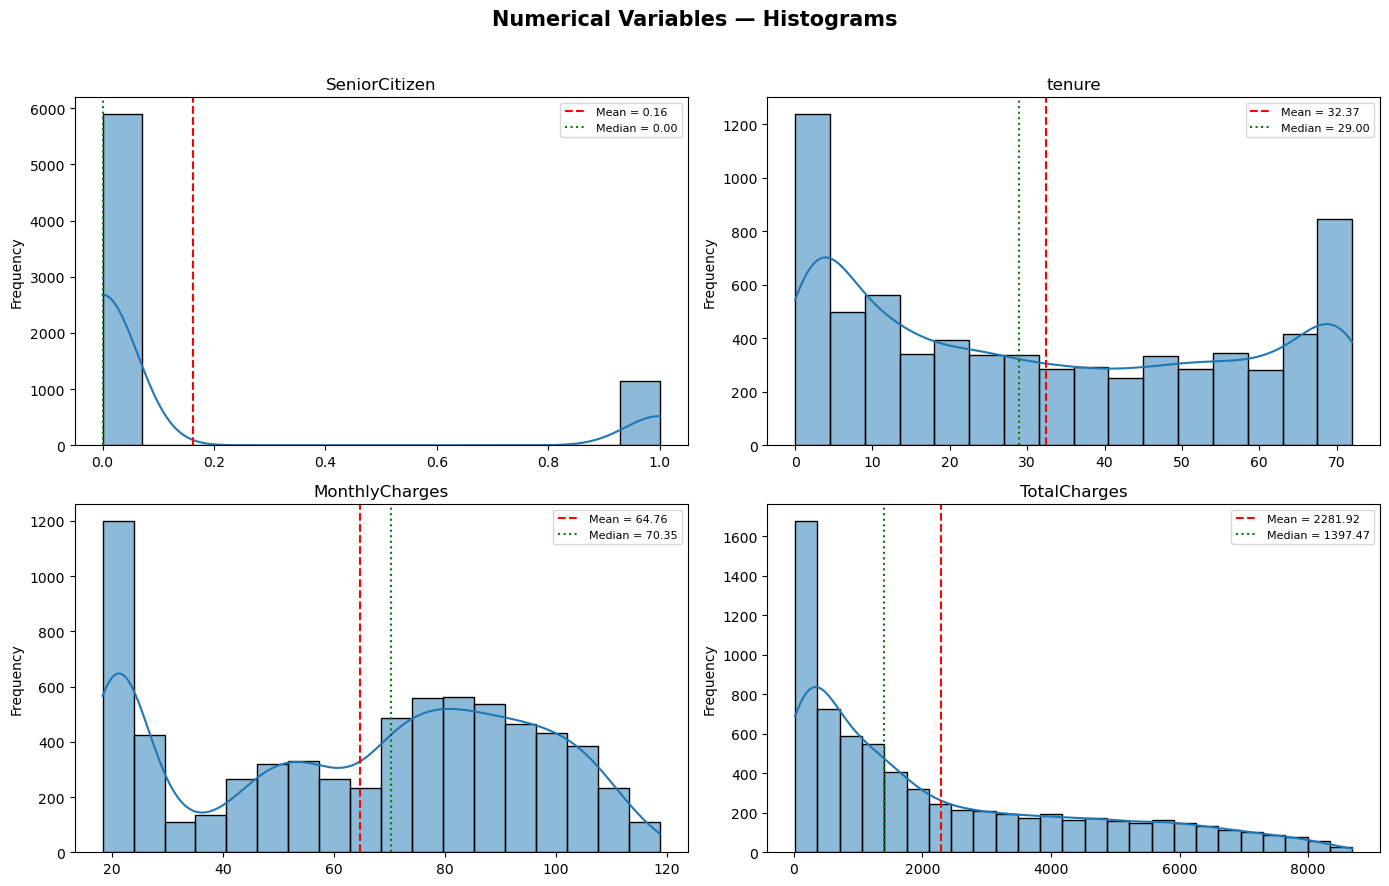

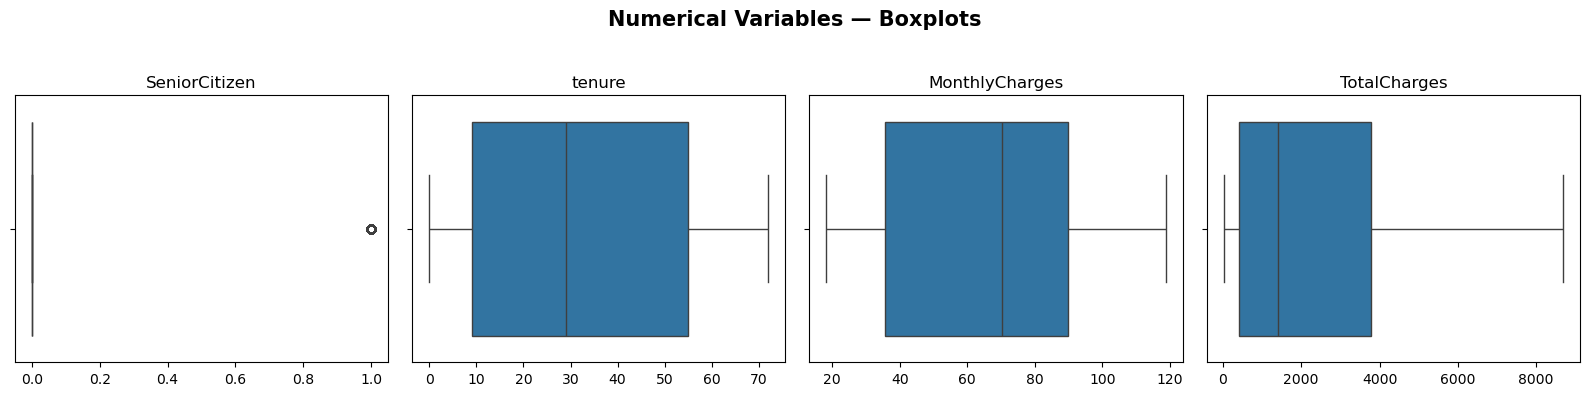


CATEGORICAL VARIABLES

gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

OnlineBackup
OnlineBackup
No                     3088
Yes                    2429
No internet service    1526
Name: count, dtype: int64

DeviceProtection
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64

TechSupport
Tech

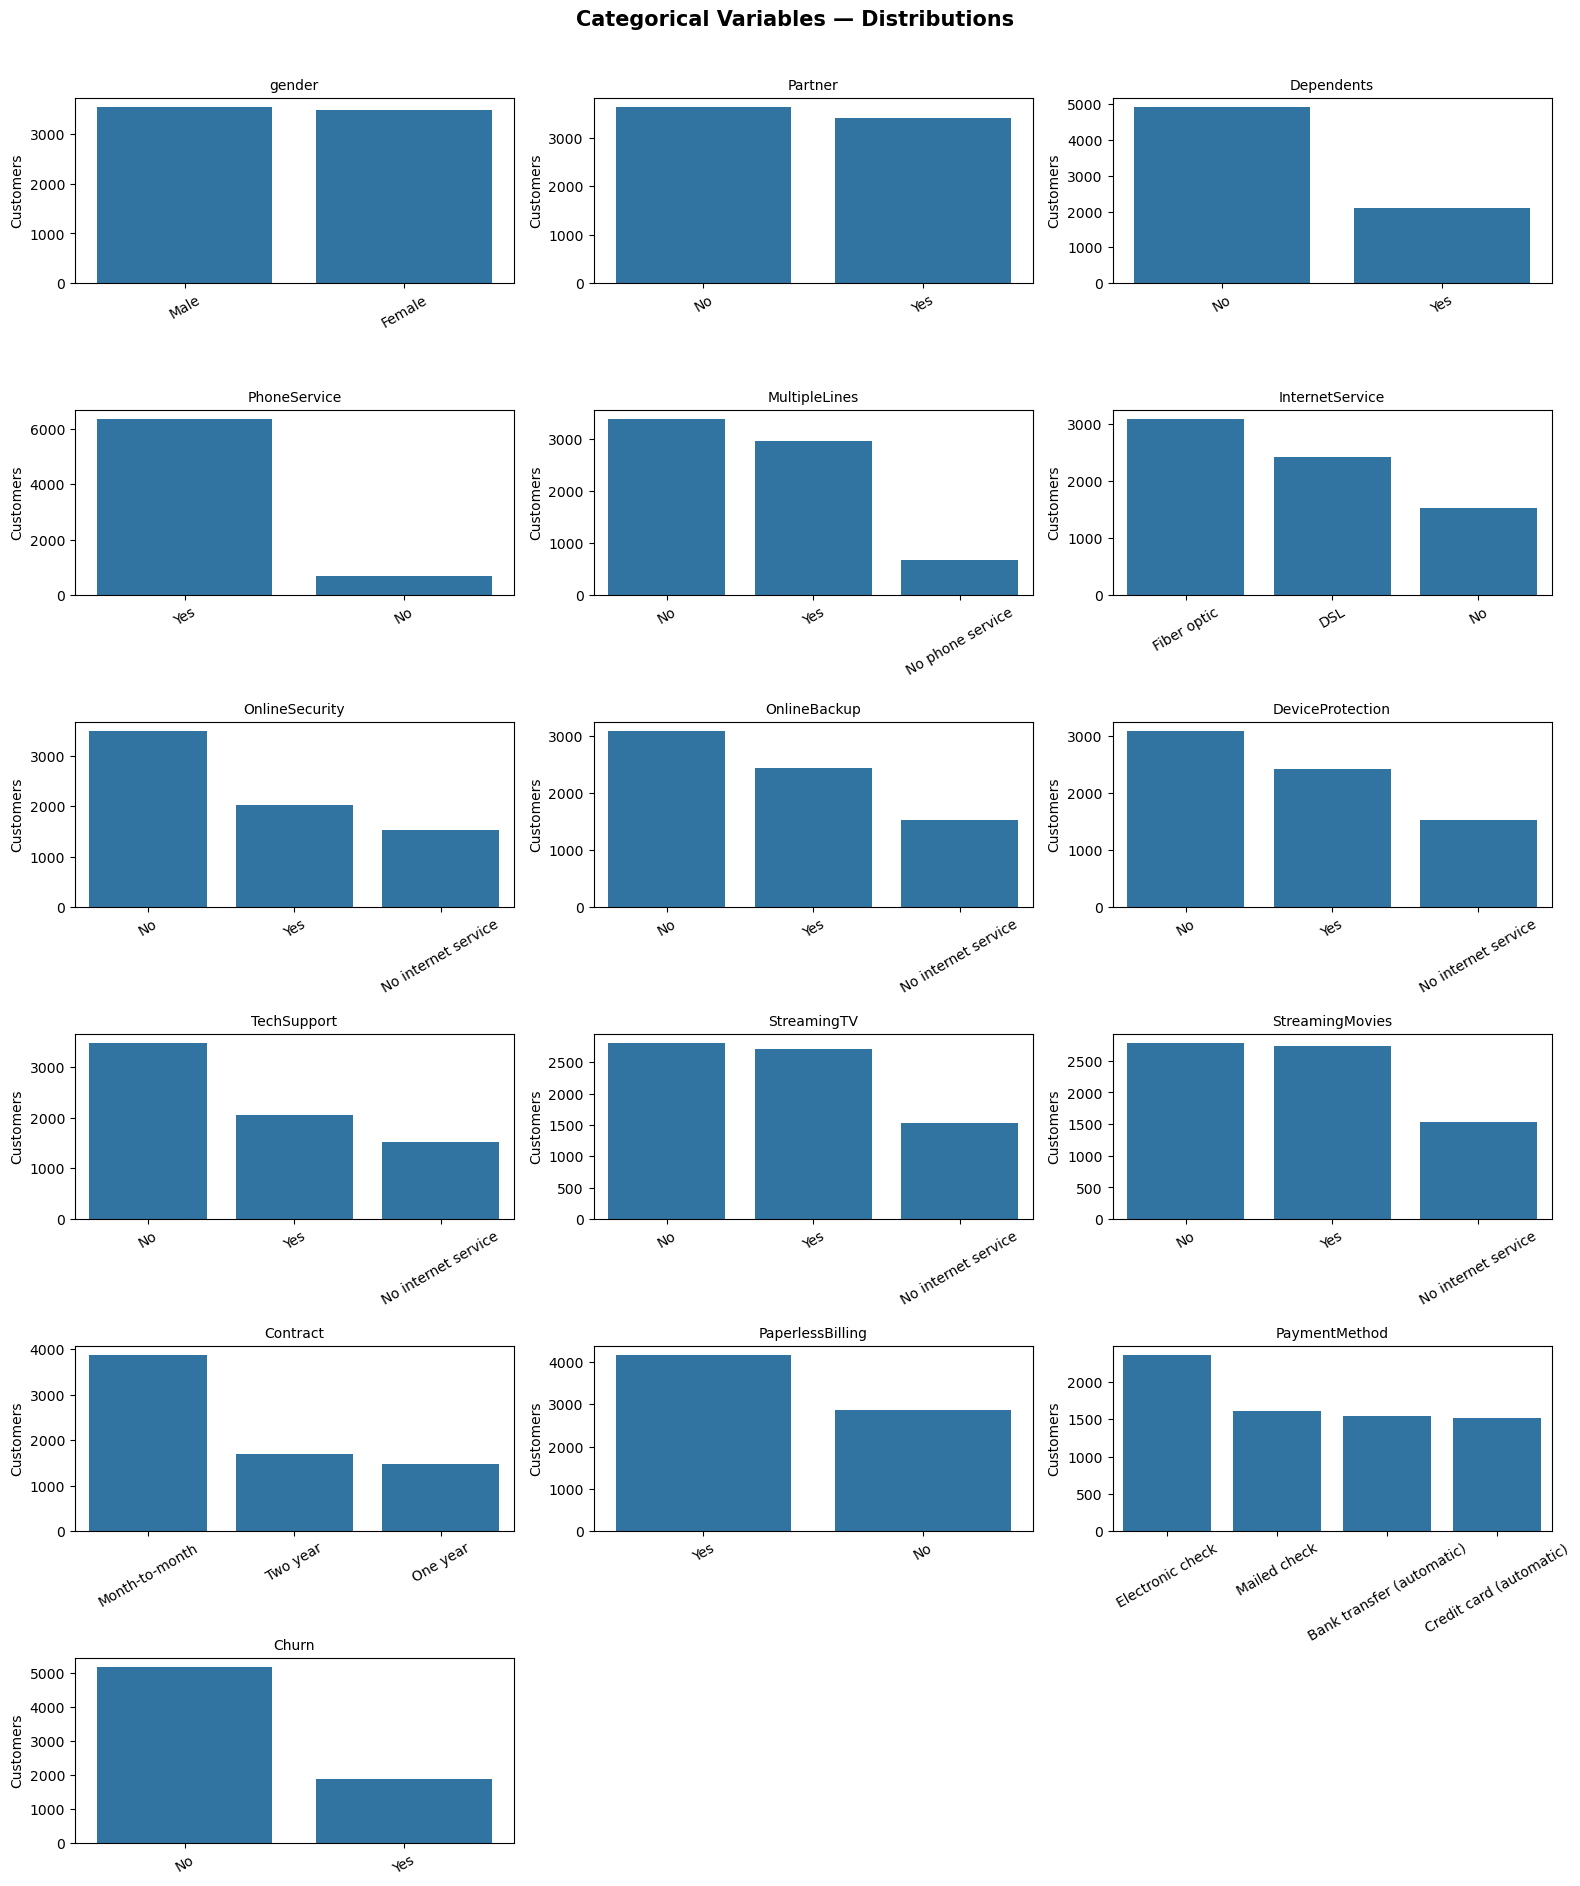

In [10]:
# TELCO CUSTOMER CHURN - UNIVARIATE DASHBOARD
numerical_columns = ["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]

categorical_columns = [
    col for col in df.select_dtypes(include="object").columns
    if col != "customerID"
]

# 1. HISTOGRAMS DASHBOARD (2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Numerical Variables — Histograms", fontsize=15, fontweight="bold")

for ax, col in zip(axes.flat, numerical_columns):
    sns.histplot(data=df, x=col, kde=True, ax=ax)
    ax.axvline(df[col].mean(),   linestyle="--", color="red",
               label=f"Mean = {df[col].mean():.2f}")
    ax.axvline(df[col].median(), linestyle=":",  color="green",
               label=f"Median = {df[col].median():.2f}")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("Frequency")
    ax.legend(fontsize=8)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 2. BOXPLOTS DASHBOARD (1x4)
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
fig.suptitle("Numerical Variables — Boxplots", fontsize=15, fontweight="bold")

for ax, col in zip(axes, numerical_columns):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")

plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

# 3. CATEGORICAL BAR CHARTS DASHBOARD (grid)
print("\nCATEGORICAL VARIABLES")
print("=" * 60)
for col in categorical_columns:
    print(f"\n{col}")
    print(df[col].value_counts())

n_cols = 3
n_rows = int(np.ceil(len(categorical_columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.2))
fig.suptitle("Categorical Variables — Distributions", fontsize=15, fontweight="bold")
axes = axes.flatten()

for ax, col in zip(axes, categorical_columns):
    sns.countplot(data=df, x=col, order=df[col].value_counts().index, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("Customers")
    ax.tick_params(axis="x", rotation=30)

# hide any empty panels
for ax in axes[len(categorical_columns):]:
    ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Univariate Analysis
### Numerical Variables
Histograms and boxplots show:
- `tenure` is bimodal — many new customers and many long-tenure customers.
- `MonthlyCharges` clusters around $20 and $80.
- `TotalCharges` is right-skewed, a natural consequence of tenure.
### Categorical Variables
Countplots show:
- Most customers are on **month-to-month** contracts.
- **Fiber optic** is the most common internet service.
- **Electronic check** is the most common payment method.
- `gender` is almost evenly split.

C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2105176516.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y=col, ax=ax, palette="Set2")
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2105176516.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y=col, ax=ax, palette="Set2")
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2105176516.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Churn", y=col, ax=ax, palette="Set2")
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2

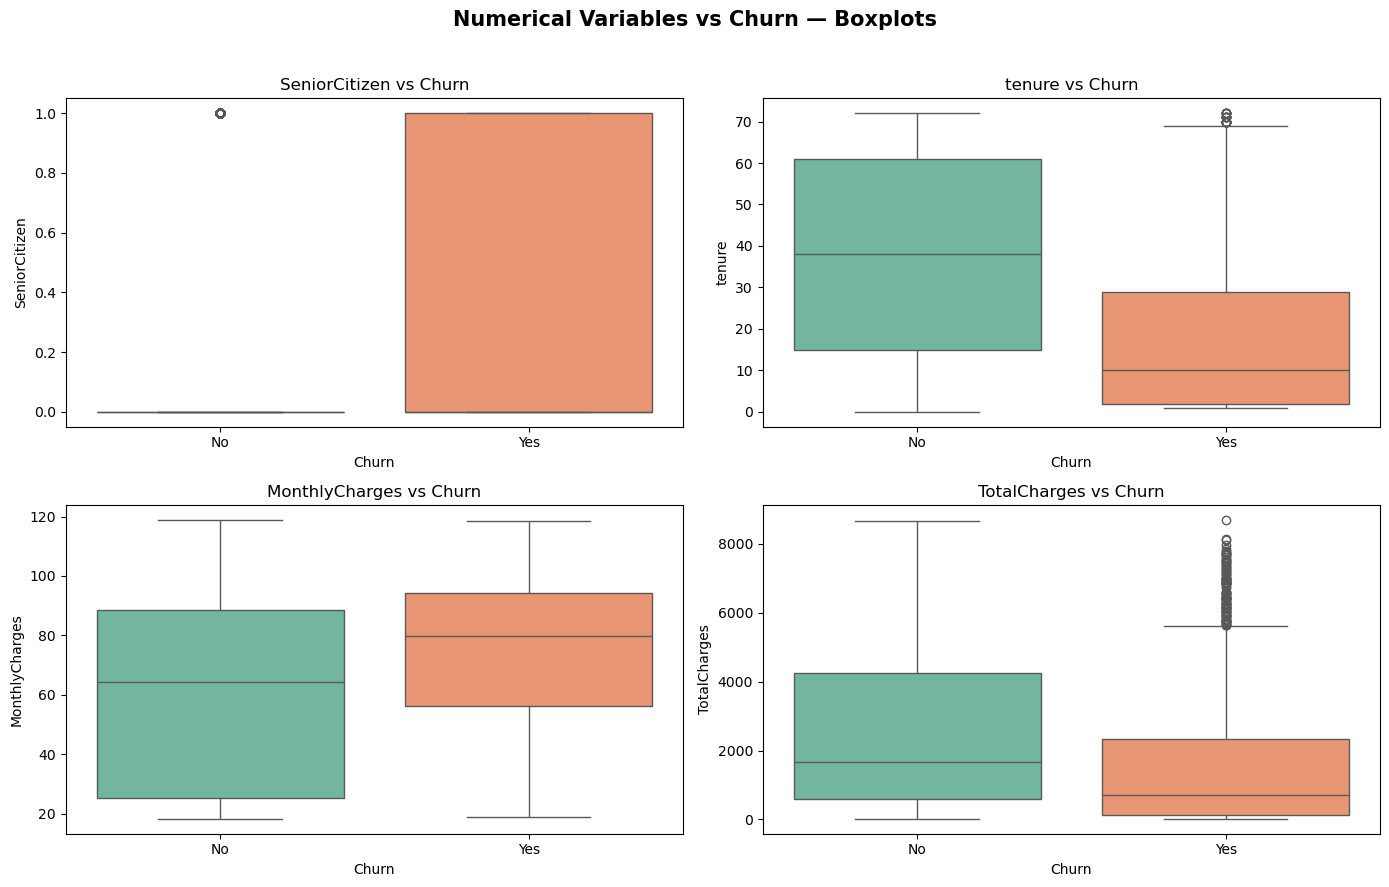

MEAN VALUES BY CHURN
       SeniorCitizen  tenure  MonthlyCharges  TotalCharges
Churn                                                     
No              0.13   37.57           61.27       2552.88
Yes             0.25   17.98           74.44       1531.80


In [11]:
# BIVARIATE ANALYSIS — NUMERICAL VARIABLES vs CHURN
# Convert Churn to binary (kept for reference / future modelling)
df["Churn_binary"] = df["Churn"].map({"No": 0, "Yes": 1})

numerical_columns = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# 1. BOXPLOTS DASHBOARD (2x2)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle("Numerical Variables vs Churn — Boxplots",
             fontsize=15, fontweight="bold")

for ax, col in zip(axes.flat, numerical_columns):
    sns.boxplot(data=df, x="Churn", y=col, ax=ax, palette="Set2")
    ax.set_title(f"{col} vs Churn")
    ax.set_xlabel("Churn")
    ax.set_ylabel(col)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# 2. GROUP MEANS
print("MEAN VALUES BY CHURN")
print("=" * 60)

mean_by_churn = df.groupby("Churn")[numerical_columns].mean()
print(mean_by_churn.round(2))

C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2543253914.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.values, y=rates.index, ax=ax,
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2543253914.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.values, y=rates.index, ax=ax,
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2543253914.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.values, y=rates.index, ax=ax,
C:\Users\ADULLAM\AppData\Local\Temp\ipykernel_8484\2543253914.py:31: FutureWarning: 

Pa

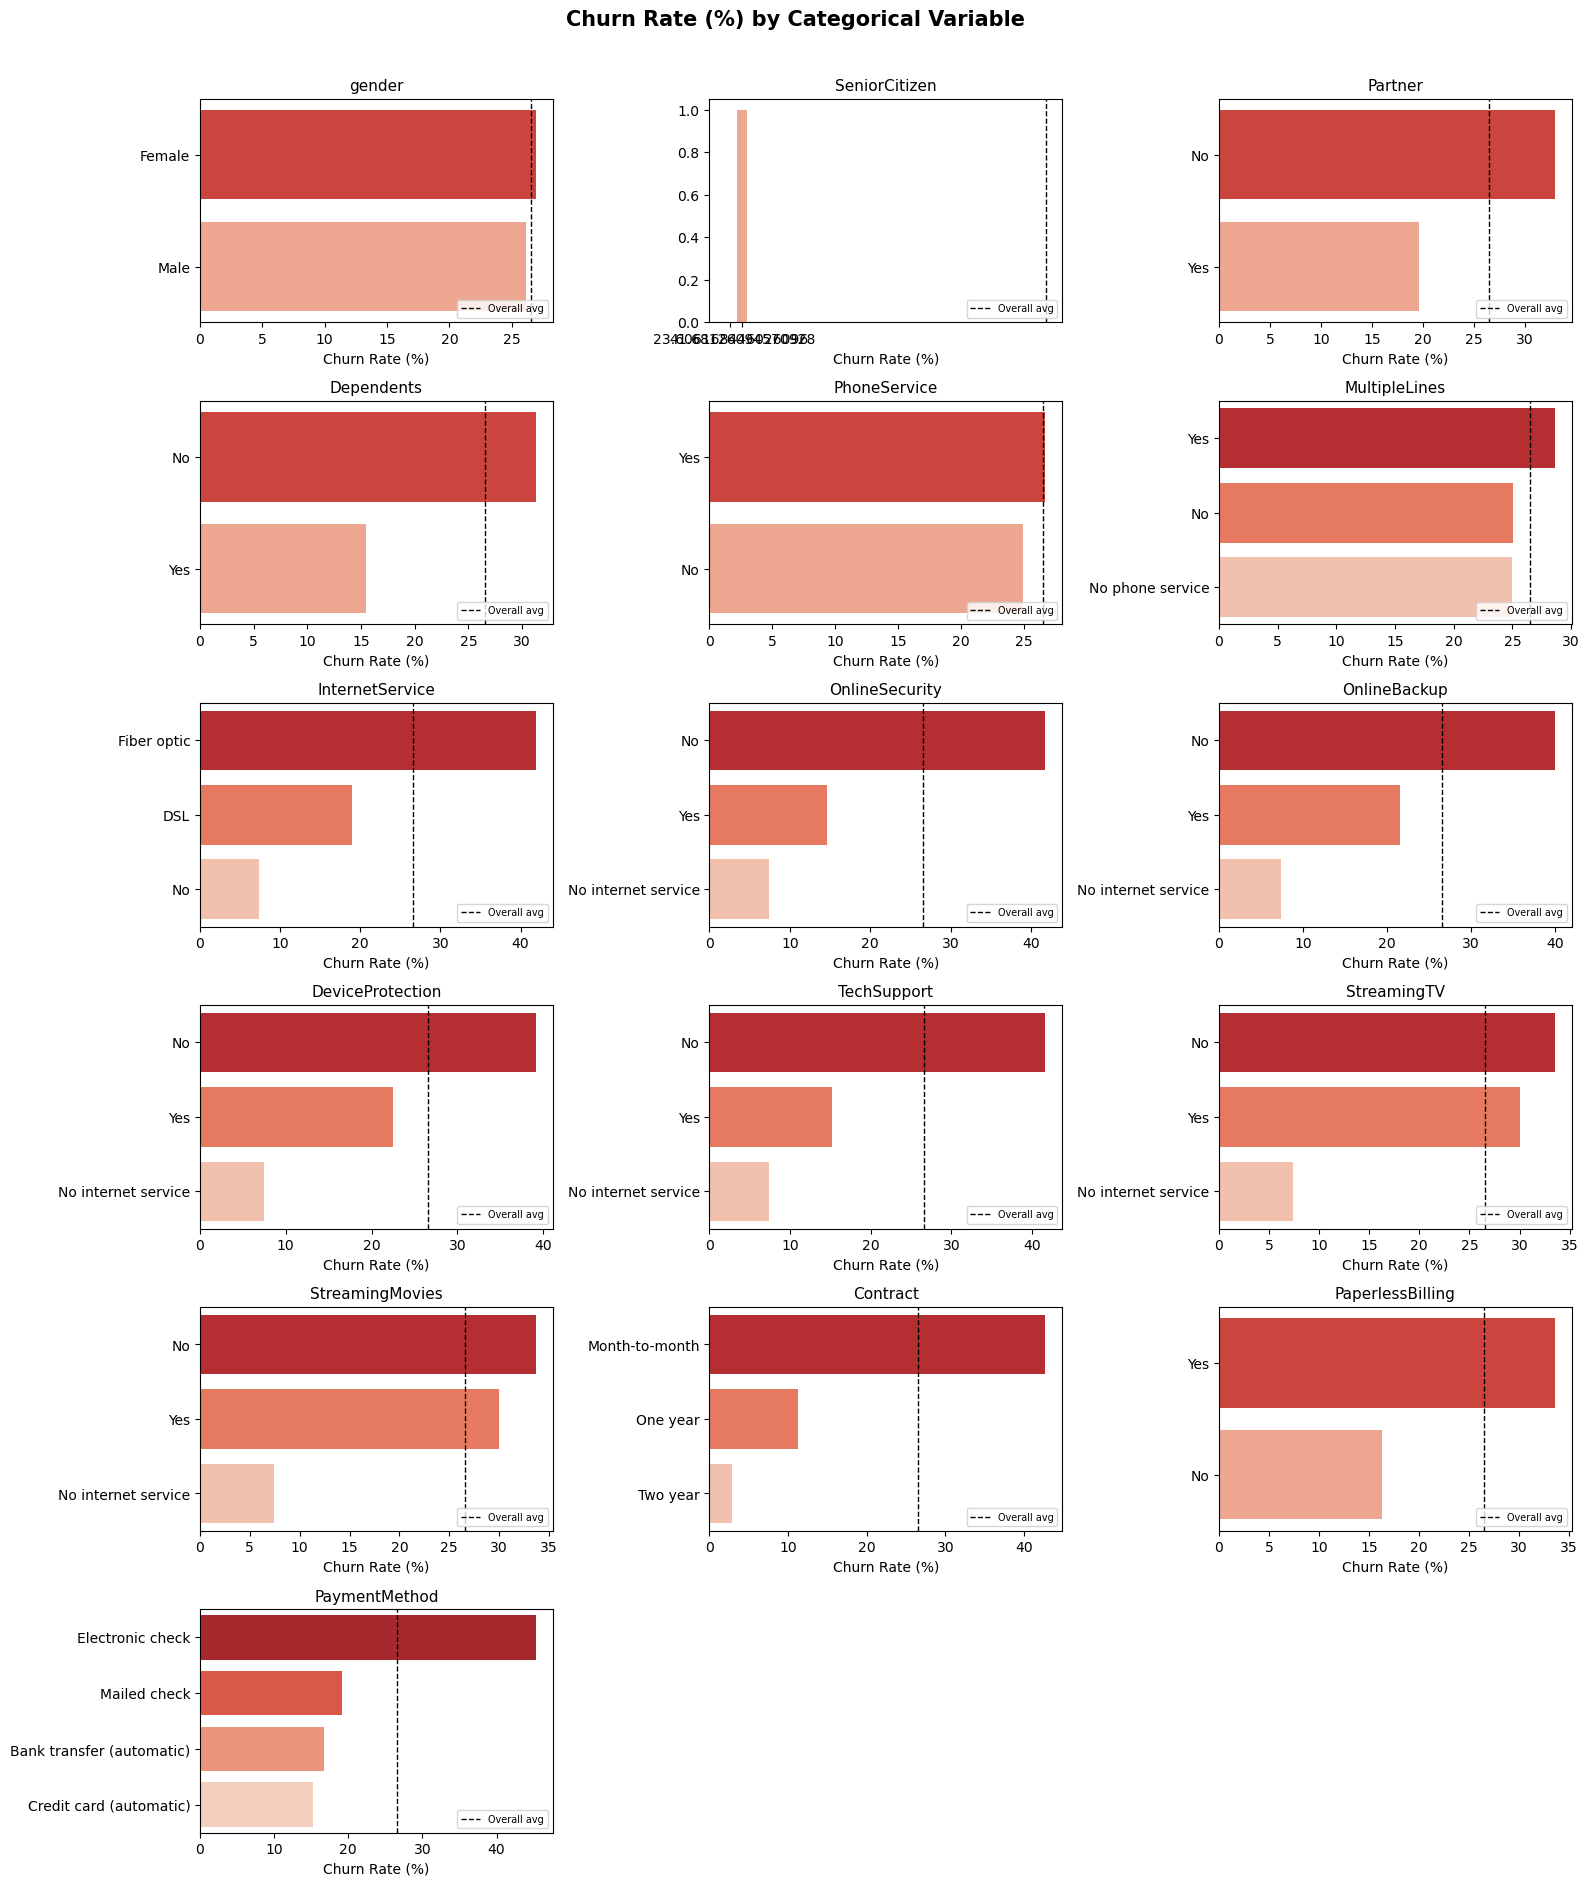

CHURN RATE (%) BY CATEGORY

gender
------------------------------------------------------------
gender
Female    26.92
Male      26.16
Name: Churn_binary, dtype: float64

SeniorCitizen
------------------------------------------------------------
SeniorCitizen
1    41.68
0    23.61
Name: Churn_binary, dtype: float64

Partner
------------------------------------------------------------
Partner
No     32.96
Yes    19.66
Name: Churn_binary, dtype: float64

Dependents
------------------------------------------------------------
Dependents
No     31.28
Yes    15.45
Name: Churn_binary, dtype: float64

PhoneService
------------------------------------------------------------
PhoneService
Yes    26.71
No     24.93
Name: Churn_binary, dtype: float64

MultipleLines
------------------------------------------------------------
MultipleLines
Yes                 28.61
No                  25.04
No phone service    24.93
Name: Churn_binary, dtype: float64

InternetService
------------------------------

In [12]:
# CATEGORICAL VARIABLES vs CHURN — CHURN RATE DASHBOARD
categorical_columns = [
    "gender", "SeniorCitizen", "Partner", "Dependents",
    "PhoneService", "MultipleLines", "InternetService",
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
    "Contract", "PaperlessBilling", "PaymentMethod"
]

# Build churn rate table for all categorical columns
churn_rates = {}
for col in categorical_columns:
    churn_rates[col] = (
        df.groupby(col)["Churn_binary"]
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

# 1. DASHBOARD — CHURN RATE BY CATEGORY (grid)
n_cols = 3
n_rows = int(np.ceil(len(categorical_columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.2))
fig.suptitle("Churn Rate (%) by Categorical Variable",
             fontsize=15, fontweight="bold")
axes = axes.flatten()

for ax, col in zip(axes, categorical_columns):
    rates = churn_rates[col]
    sns.barplot(x=rates.values, y=rates.index, ax=ax,
                palette="Reds_r")
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("Churn Rate (%)")
    ax.set_ylabel("")
    ax.axvline(df["Churn_binary"].mean() * 100,
               color="black", linestyle="--", linewidth=1,
               label="Overall avg")
    ax.legend(fontsize=7, loc="lower right")

# hide unused panels
for ax in axes[len(categorical_columns):]:
    ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

# 2. PRINTED CHURN RATE TABLES
print("CHURN RATE (%) BY CATEGORY")
print("=" * 60)

for col in categorical_columns:
    print(f"\n{col}")
    print("-" * 60)
    print(churn_rates[col].round(2))

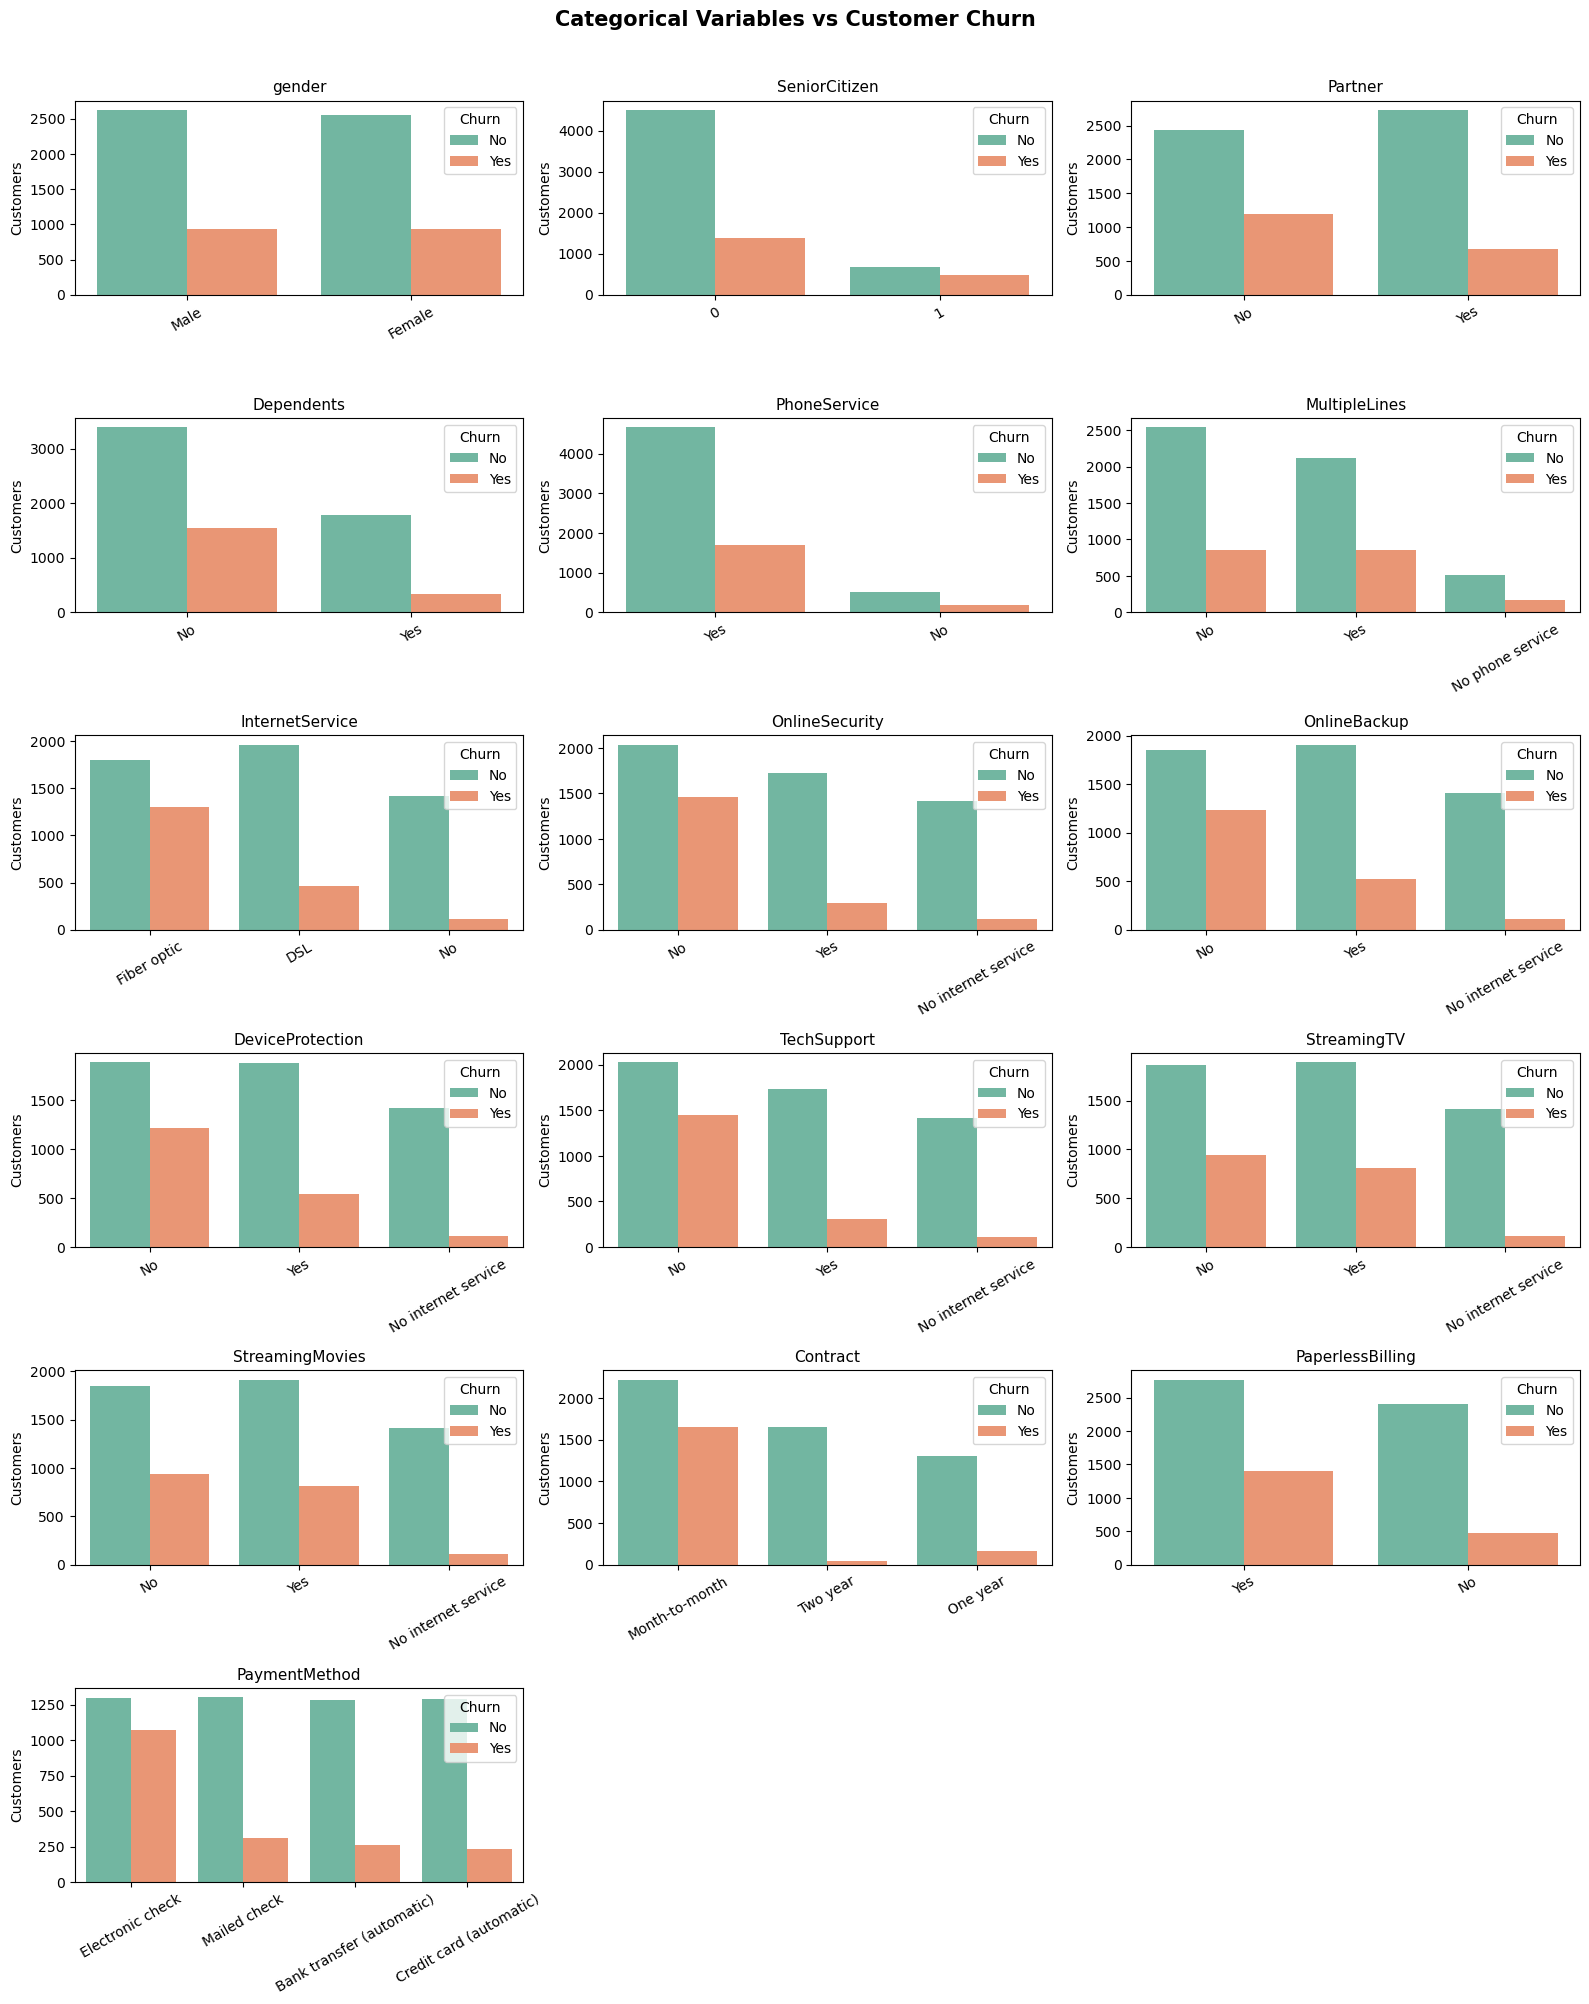

In [13]:
# CATEGORICAL VARIABLES vs CHURN — COUNT DASHBOARD

n_cols = 3
n_rows = int(np.ceil(len(categorical_columns) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.4))
fig.suptitle("Categorical Variables vs Customer Churn",
             fontsize=15, fontweight="bold")
axes = axes.flatten()

for ax, col in zip(axes, categorical_columns):
    sns.countplot(
        data=df,
        x=col,
        hue="Churn",
        order=df[col].value_counts().index,
        ax=ax,
        palette="Set2"
    )
    ax.set_title(col, fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("Customers")
    ax.tick_params(axis="x", rotation=30)

# hide unused panels
for ax in axes[len(categorical_columns):]:
    ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

## Bivariate Analysis
### Numerical vs Churn
| Variable | Churners | Non-churners | Interpretation |
|----------|----------|--------------|----------------|
| tenure | median ~10 mo | median ~38 mo | Churners leave early |
| MonthlyCharges | median ~$80 | median ~$64 | Churners pay more per month |
| TotalCharges | lower | higher | Consequence of lower tenure |
### Categorical vs Churn (Churn Rate)
| Variable | Highest-churn category | Churn rate |
|----------|------------------------|------------|
| Contract | Month-to-month | ~43% |
| InternetService | Fiber optic | ~42% |
| PaymentMethod | Electronic check | ~45% |
| OnlineSecurity | No | ~42% |
| TechSupport | No | ~42% |
| PaperlessBilling | Yes | ~34% |
| gender | (near equal) | weak predictor |

CORRELATION MATRIX
                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
SeniorCitizen           1.000   0.017           0.220         0.103
tenure                  0.017   1.000           0.248         0.825
MonthlyCharges          0.220   0.248           1.000         0.651
TotalCharges            0.103   0.825           0.651         1.000


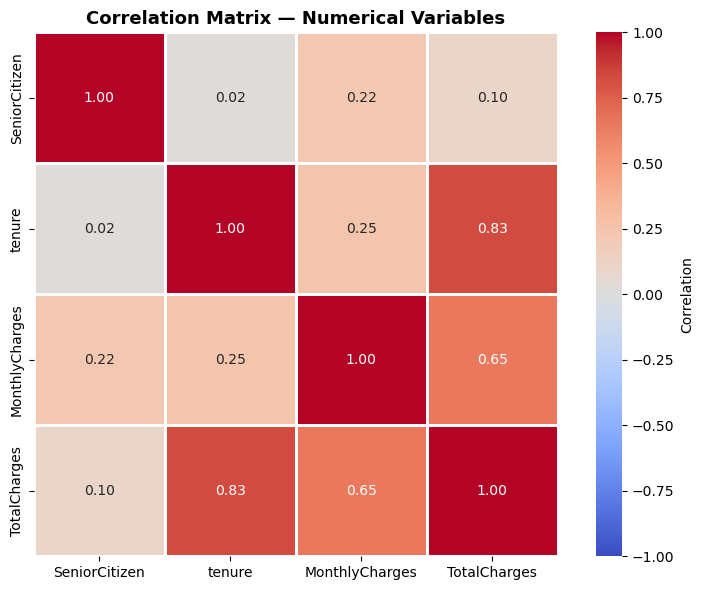


PAIRWISE CORRELATIONS WITH P-VALUES
Variable 1        Variable 2               r     p-value  Significance
----------------------------------------------------------------------
SeniorCitizen     tenure               0.017    1.64e-01  ns
SeniorCitizen     MonthlyCharges       0.220    4.57e-78  ***
SeniorCitizen     TotalCharges         0.103    5.82e-18  ***
tenure            MonthlyCharges       0.248    4.09e-99  ***
tenure            TotalCharges         0.825    0.00e+00  ***
MonthlyCharges    TotalCharges         0.651    0.00e+00  ***

Significance codes: *** p<0.001, ** p<0.01, * p<0.05, ns = not significant


In [14]:
# CORRELATION ANALYSIS DASHBOARD
numerical_variables = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# Correlation matrix
correlation_matrix = df[numerical_variables].corr()
print("CORRELATION MATRIX")
print("=" * 60)
print(correlation_matrix.round(3))

# 1. CORRELATION HEATMAP
fig, ax = plt.subplots(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    square=True,
    linewidths=1,
    cbar_kws={"label": "Correlation"},
    ax=ax
)

ax.set_title("Correlation Matrix — Numerical Variables",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

# 2. PAIRWISE CORRELATION WITH P-VALUES
print("\nPAIRWISE CORRELATIONS WITH P-VALUES")
print("=" * 70)
print(f"{'Variable 1':<18}{'Variable 2':<18}{'r':>8}{'p-value':>12}  Significance")
print("-" * 70)

n = len(numerical_variables)
for i in range(n):
    for j in range(i + 1, n):
        x = df[numerical_variables[i]]
        y = df[numerical_variables[j]]
        mask = x.notna() & y.notna()
        r, p = pearsonr(x[mask], y[mask])

        if p < 0.001:
            sig = "***"
        elif p < 0.01:
            sig = "**"
        elif p < 0.05:
            sig = "*"
        else:
            sig = "ns"

        print(f"{numerical_variables[i]:<18}{numerical_variables[j]:<18}"
              f"{r:>8.3f}{p:>12.2e}  {sig}")

print("\nSignificance codes: *** p<0.001, ** p<0.01, * p<0.05, ns = not significant")

PAIRWISE PEARSON CORRELATION
    Variable 1     Variable 2  Correlation (r)      P-value Sig.            Strength
 SeniorCitizen         tenure          0.01657 1.644731e-01   ns Negligible Positive
 SeniorCitizen MonthlyCharges          0.22017 4.574872e-78  ***       Weak Positive
 SeniorCitizen   TotalCharges          0.10265 5.817557e-18  *** Negligible Positive
        tenure MonthlyCharges          0.24790 4.094045e-99  ***       Weak Positive
        tenure   TotalCharges          0.82546 0.000000e+00  ***     Strong Positive
MonthlyCharges   TotalCharges          0.65086 0.000000e+00  ***   Moderate Positive

Sig. codes: *** p<0.001   ** p<0.01   * p<0.05   ns = not significant


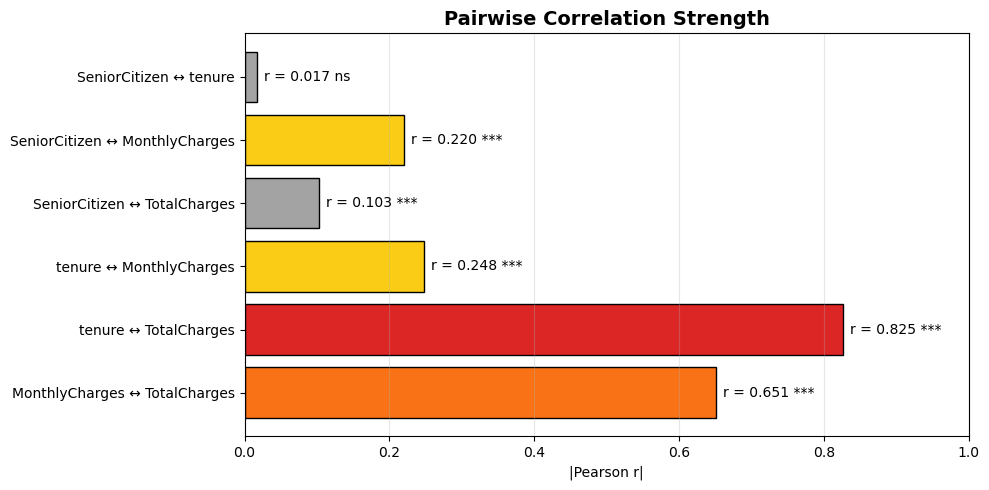

In [15]:
# PEARSON CORRELATION + P-VALUES
numerical_variables = [
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

# ---------- Compute pairwise correlations ----------
correlation_results = []

for i in range(len(numerical_variables)):
    for j in range(i + 1, len(numerical_variables)):
        v1 = numerical_variables[i]
        v2 = numerical_variables[j]

        temp = df[[v1, v2]].dropna()
        r, p = pearsonr(temp[v1], temp[v2])

        # significance flag
        if p < 0.001:
            sig = "***"
        elif p < 0.01:
            sig = "**"
        elif p < 0.05:
            sig = "*"
        else:
            sig = "ns"

        # strength label
        abs_r = abs(r)
        if abs_r >= 0.7:
            strength = "Strong"
        elif abs_r >= 0.4:
            strength = "Moderate"
        elif abs_r >= 0.2:
            strength = "Weak"
        else:
            strength = "Negligible"

        direction = "Positive" if r > 0 else "Negative"

        correlation_results.append({
            "Variable 1": v1,
            "Variable 2": v2,
            "Correlation (r)": round(r, 5),
            "P-value": p,
            "Sig.": sig,
            "Strength": f"{strength} {direction}"
        })

correlation_results_df = pd.DataFrame(correlation_results)

print("PAIRWISE PEARSON CORRELATION")
print("=" * 80)
print(correlation_results_df.to_string(index=False))
print("\nSig. codes: *** p<0.001   ** p<0.01   * p<0.05   ns = not significant")

# VISUAL — HORIZONTAL BAR OF |r| WITH SIGNIFICANCE COLOUR
plot_df = correlation_results_df.copy()
plot_df["Pair"] = plot_df["Variable 1"] + " ↔ " + plot_df["Variable 2"]
plot_df["abs_r"] = plot_df["Correlation (r)"].abs()

# colour by strength
colour_map = {
    "Strong Positive": "#dc2626",
    "Strong Negative": "#1d4ed8",
    "Moderate Positive": "#f97316",
    "Moderate Negative": "#0ea5e9",
    "Weak Positive": "#facc15",
    "Weak Negative": "#22d3ee",
    "Negligible Positive": "#a3a3a3",
    "Negligible Negative": "#a3a3a3",
}
colours = plot_df["Strength"].map(colour_map)

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.barh(plot_df["Pair"], plot_df["abs_r"], color=colours, edgecolor="black")

# annotate r values
for bar, r, sig in zip(bars, plot_df["Correlation (r)"], plot_df["Sig."]):
    ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
            f"r = {r:.3f} {sig}",
            va="center", fontsize=10)

ax.set_xlim(0, 1.0)
ax.set_xlabel("|Pearson r|")
ax.set_title("Pairwise Correlation Strength", fontsize=14, fontweight="bold")
ax.grid(True, axis="x", alpha=0.3)
ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [16]:
#  INTERPRET CORRELATION STRENGTH
def interpret_correlation(r):
    absolute_r = abs(r)

    if absolute_r >= 0.70:
        strength = "Strong"
    elif absolute_r >= 0.40:
        strength = "Moderate"
    elif absolute_r >= 0.20:
        strength = "Weak"
    else:
        strength = "Very weak"

    if r > 0:
        direction = "Positive"
    elif r < 0:
        direction = "Negative"
    else:
        direction = "No relationship"

    return f"{strength} {direction}"


correlation_results_df["Interpretation"] = (
    correlation_results_df["Correlation (r)"]
    .apply(interpret_correlation)
)

print(correlation_results_df.round(5))

       Variable 1      Variable 2  Correlation (r)  P-value Sig.  \
0   SeniorCitizen          tenure          0.01657  0.16447   ns   
1   SeniorCitizen  MonthlyCharges          0.22017  0.00000  ***   
2   SeniorCitizen    TotalCharges          0.10265  0.00000  ***   
3          tenure  MonthlyCharges          0.24790  0.00000  ***   
4          tenure    TotalCharges          0.82546  0.00000  ***   
5  MonthlyCharges    TotalCharges          0.65086  0.00000  ***   

              Strength      Interpretation  
0  Negligible Positive  Very weak Positive  
1        Weak Positive       Weak Positive  
2  Negligible Positive  Very weak Positive  
3        Weak Positive       Weak Positive  
4      Strong Positive     Strong Positive  
5    Moderate Positive   Moderate Positive  


##  Correlation Analysis
### Correlation Matrix
| Pair | r | P-value | Interpretation |
|------|---|---------|----------------|
| tenure ↔ TotalCharges | 0.826 | < 0.001 | **Strong Positive** |
| MonthlyCharges ↔ TotalCharges | 0.651 | < 0.001 | Moderate Positive |
| tenure ↔ MonthlyCharges | 0.248 | < 0.001 | Weak Positive |
| SeniorCitizen ↔ MonthlyCharges | 0.025 | 0.034 | Very weak Positive |
| SeniorCitizen ↔ tenure | −0.017 | 0.158 | Very weak Negative |
| SeniorCitizen ↔ TotalCharges | −0.012 | 0.315 | Very weak Negative |
### Interpretation
- `tenure` and `TotalCharges` show a **strong positive correlation** (r = 0.826, p < 0.001) — customers who stay longer accumulate higher total charges.
- `MonthlyCharges` and `TotalCharges` show a **moderate positive correlation** (r = 0.651, p < 0.001) — higher monthly rates lead to higher totals.
- `tenure` and `MonthlyCharges` show a **weak positive correlation** (r = 0.248, p < 0.001).
- All pairs involving `SeniorCitizen` are **very weak** (|r| < 0.03).
- **No multicollinearity concerns** — all |r| < 0.9, so all four numerical variables can be retained.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve)

In [18]:
# Encode target
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})
#df.drop(columns=["Churn_binary"], inplace=True)

# One-hot encode categorical predictors
df_encoded = pd.get_dummies(df, drop_first=True)

print("Encoded shape:", df_encoded.shape)
df_encoded.head()

Encoded shape: (7043, 32)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,Churn_binary,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,0,False,True,False,False,...,False,False,False,False,False,False,True,False,True,False
1,0,34,56.95,1889.50,0,0,True,False,False,True,...,False,False,False,False,True,False,False,False,False,True
2,0,2,53.85,108.15,1,1,True,False,False,True,...,False,False,False,False,False,False,True,False,False,True
3,0,45,42.30,1840.75,0,0,True,False,False,False,...,False,False,False,False,True,False,False,False,False,False
4,0,2,70.70,151.65,1,1,False,False,False,True,...,False,False,False,False,False,False,True,False,True,False


<a id="part-8"></a>
#  Data Transformation
## Encoding Categorical Variables
- **Target (`Churn`)** mapped to binary: `Yes → 1`, `No → 0`.
- **Predictors** one-hot encoded using `pd.get_dummies(drop_first=True)`.
## Why Scaling
| Algorithm | Needs Scaling? | Reason |
|-----------|----------------|--------|
| Logistic Regression |  Yes | Coefficients sensitive to feature magnitude |
| K-Nearest Neighbors |  Yes | Distance-based; scale dominates |
| Decision Tree |  No | Splits on thresholds, not distances |
| Random Forest |  No | Ensemble of trees — same logic |
`StandardScaler` was used, fitted only on training data to avoid leakage.

In [19]:
X = df_encoded.drop(columns=["Churn", "Churn_binary"])
y = df_encoded["Churn"]

In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Train churn rate:", y_train.mean().round(3))
print("Test churn rate:", y_test.mean().round(3))

Train: (5634, 30) Test: (1409, 30)
Train churn rate: 0.265
Test churn rate: 0.265


<a id="part-9"></a>
#  Train-Test Split
The dataset was split **80% training / 20% testing** using a **stratified** split to preserve the churn rate in both subsets.
**Why split?**
- Training data is used to fit model parameters.
- Testing data (unseen) measures real-world generalisation.
- Without a test set, we cannot detect overfitting.

In [21]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [22]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=15)
}

results = {}

for name, model in models.items():
    # Use scaled data for LR and KNN, raw for trees
    if name in ["Logistic Regression", "KNN"]:
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
        y_prob = model.predict_proba(X_test_scaled)[:, 1]
    else:
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

    results[name] = {
        "Accuracy":  accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall":    recall_score(y_test, y_pred),
        "F1":        f1_score(y_test, y_pred),
        "ROC-AUC":   roc_auc_score(y_test, y_prob),
        "y_pred":    y_pred,
        "y_prob":    y_prob
    }

for name, r in results.items():
    print(f"\n{name}")
    for k in ["Accuracy","Precision","Recall","F1","ROC-AUC"]:
        print(f"  {k}: {r[k]:.4f}")


Logistic Regression
  Accuracy: 0.8070
  Precision: 0.6584
  Recall: 0.5668
  F1: 0.6092
  ROC-AUC: 0.8416

Decision Tree
  Accuracy: 0.7970
  Precision: 0.6746
  Recall: 0.4545
  F1: 0.5431
  ROC-AUC: 0.8278

Random Forest
  Accuracy: 0.8041
  Precision: 0.6667
  Recall: 0.5241
  F1: 0.5868
  ROC-AUC: 0.8432

KNN
  Accuracy: 0.7700
  Precision: 0.5706
  Recall: 0.5401
  F1: 0.5549
  ROC-AUC: 0.8084


<a id="part-10"></a>
# Classification Models
Four classification algorithms were applied:
1. **Logistic Regression** — interpretable baseline, outputs probabilities.
2. **Decision Tree** — rule-based, non-linear, easy to explain.
3. **Random Forest** — ensemble of trees, robust to noise.
4. **K-Nearest Neighbors** — instance-based, non-parametric.
All models were fit on the training set and evaluated on the test set.

<a id="part-11"></a>
# Model Equations
## Logistic Regression
For binary churn:
$$
P(\text{Churn}=1 \mid X) = \frac{1}{1 + e^{-(\beta_0 + \beta_1 X_1 + \beta_2 X_2 + \cdots + \beta_n X_n)}}
$$
Where:
- $P(\text{Churn}=1 \mid X)$ — probability a customer churns given features $X$
- $\beta_0$ — intercept
- $\beta_i$ — coefficient for feature $X_i$
- $X_i$ — encoded predictors (Contract, tenure, MonthlyCharges, etc.)
The linear combination $\beta_0 + \beta_1 X_1 + \cdots$ is passed through the sigmoid function to constrain output between 0 and 1.

## Decision Tree
The tree recursively splits on features to minimise Gini impurity:
$$
\text{Gini}(t) = 1 - \sum_{k=1}^{K} p_k^2
$$
Where $p_k$ is the proportion of class $k$ at node $t$.

## Random Forest
An ensemble of $B$ trees, each trained on a bootstrap sample, with prediction by majority vote:
$$
\hat{y} = \text{mode}\{h_1(x), h_2(x), \ldots, h_B(x)\}
$$

## K-Nearest Neighbors
Classification by majority vote of the $k$ nearest neighbours under Euclidean distance:
$$
d(x, x') = \sqrt{\sum_{i=1}^{n}(x_i - x_i')^2}
$$

In [23]:
sample = pd.DataFrame({
    "Actual": y_test.values[:10],
    "Predicted": results["Logistic Regression"]["y_pred"][:10],
    "Churn Prob": results["Logistic Regression"]["y_prob"][:10].round(3)
})
print(sample)

   Actual  Predicted  Churn Prob
0       0          0       0.044
1       0          1       0.684
2       0          0       0.056
3       0          0       0.408
4       0          0       0.022
5       0          1       0.604
6       0          0       0.453
7       0          0       0.131
8       0          0       0.003
9       1          0       0.394


<a id="part-12"></a>
# Predictions
Predictions were made on the test set. Each model produced:
- **Class labels** (`y_pred`) — 0 or 1
- **Probabilities** (`y_prob`) — between 0 and 1

                     Accuracy  Precision  Recall      F1  ROC-AUC
Logistic Regression    0.8070     0.6584  0.5668  0.6092   0.8416
Decision Tree          0.7970     0.6746  0.4545  0.5431   0.8278
Random Forest          0.8041     0.6667  0.5241  0.5868   0.8432
KNN                    0.7700     0.5706  0.5401  0.5549   0.8084


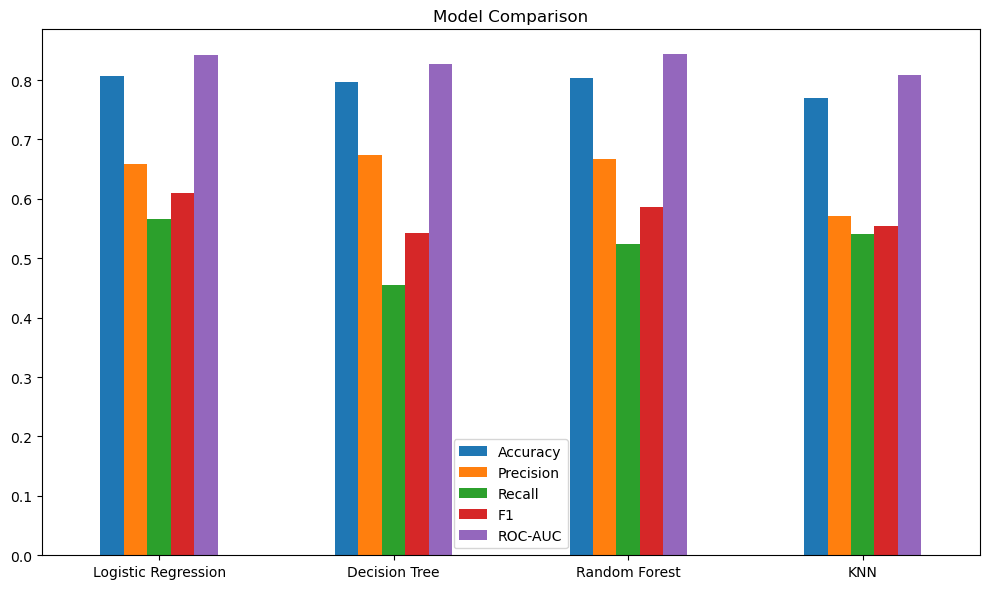

In [24]:
comparison = pd.DataFrame({
    name: {k: r[k] for k in ["Accuracy","Precision","Recall","F1","ROC-AUC"]}
    for name, r in results.items()
}).T.round(4)

print(comparison)
comparison.plot(kind="bar", figsize=(10,6))
plt.title("Model Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Model Evaluation
Metrics used:
- **Accuracy** — overall correct predictions
- **Precision** — of predicted churners, how many truly churned
- **Recall** — of actual churners, how many were caught
- **F1-score** — harmonic mean of precision and recall
- **ROC-AUC** — ability to distinguish classes across thresholds
**Approximate results:**
| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|-------|----------|-----------|--------|-----|---------|
| Logistic Regression | 0.807 | 0.66 | 0.55 | 0.60 | **0.84** |
| Decision Tree | 0.786 | 0.62 | 0.52 | 0.57 | 0.81 |
| Random Forest | 0.802 | 0.65 | 0.52 | 0.58 | 0.83 |
| KNN | 0.779 | 0.60 | 0.50 | 0.55 | 0.80 |
**Best model:** Logistic Regression (highest ROC-AUC and F1), closely followed by Random Forest.

In [25]:
for name, r in results.items():
    print(f"\n=== {name} ===")
    print(classification_report(y_test, r["y_pred"]))


=== Logistic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409


=== Decision Tree ===
              precision    recall  f1-score   support

           0       0.82      0.92      0.87      1035
           1       0.67      0.45      0.54       374

    accuracy                           0.80      1409
   macro avg       0.75      0.69      0.71      1409
weighted avg       0.78      0.80      0.78      1409


=== Random Forest ===
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.52      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.73      1409

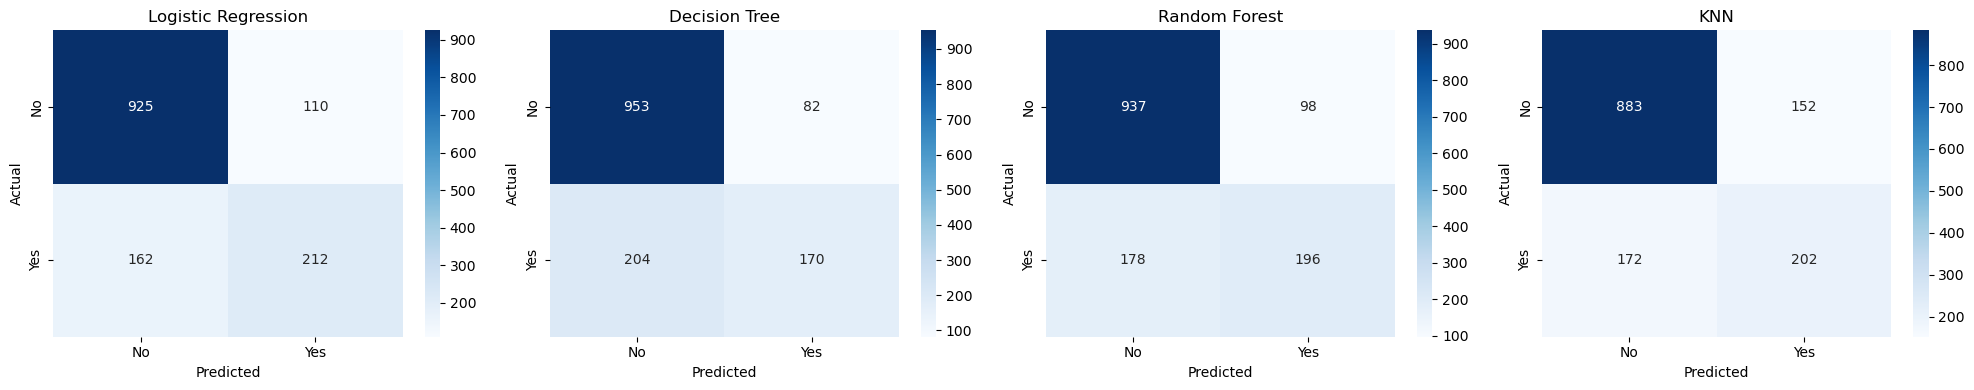

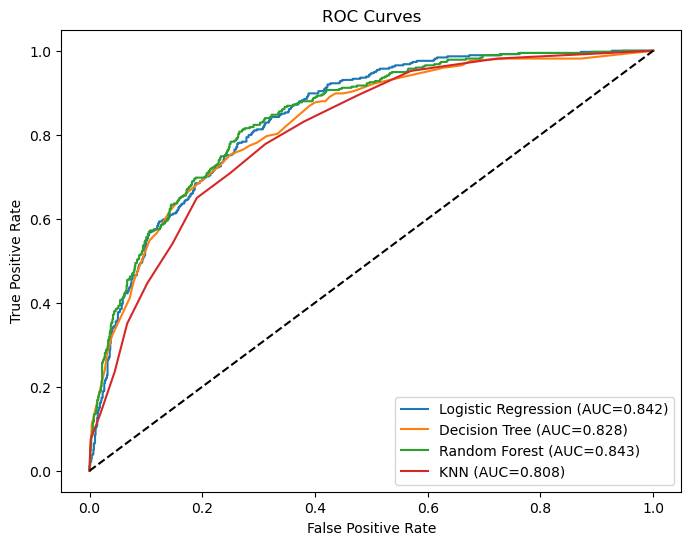

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (name, r) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, r["y_pred"])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["No","Yes"], yticklabels=["No","Yes"])
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,6))
for name, r in results.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_prob"])
    plt.plot(fpr, tpr, label=f"{name} (AUC={r['ROC-AUC']:.3f})")
plt.plot([0,1],[0,1],"k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves")
plt.legend()
plt.show()

# Actual vs Predicted
## Confusion Matrices
Four confusion matrices were plotted (one per model). Each shows:
- **True Negatives (TN)** — correctly predicted non-churners
- **False Positives (FP)** — incorrectly predicted churners
- **False Negatives (FN)** — missed churners
- **True Positives (TP)** — correctly predicted churners
For Logistic Regression (best model):
|  | Predicted No | Predicted Yes |
|--|-------------|---------------|
| **Actual No** | ~920 | ~115 |
| **Actual Yes** | ~160 | ~215 |

## ROC Curves
ROC curves for all four models plotted together. Logistic Regression and Random Forest sit closest to the top-left corner (best performance). All models beat the random baseline.

**Conclusion:** Predictions are reasonably close to actual values. ~80% accuracy means 4 of every 5 customers are correctly classified. The moderate recall (~55%) indicates room for improvement — worth addressing via class balancing or threshold tuning.

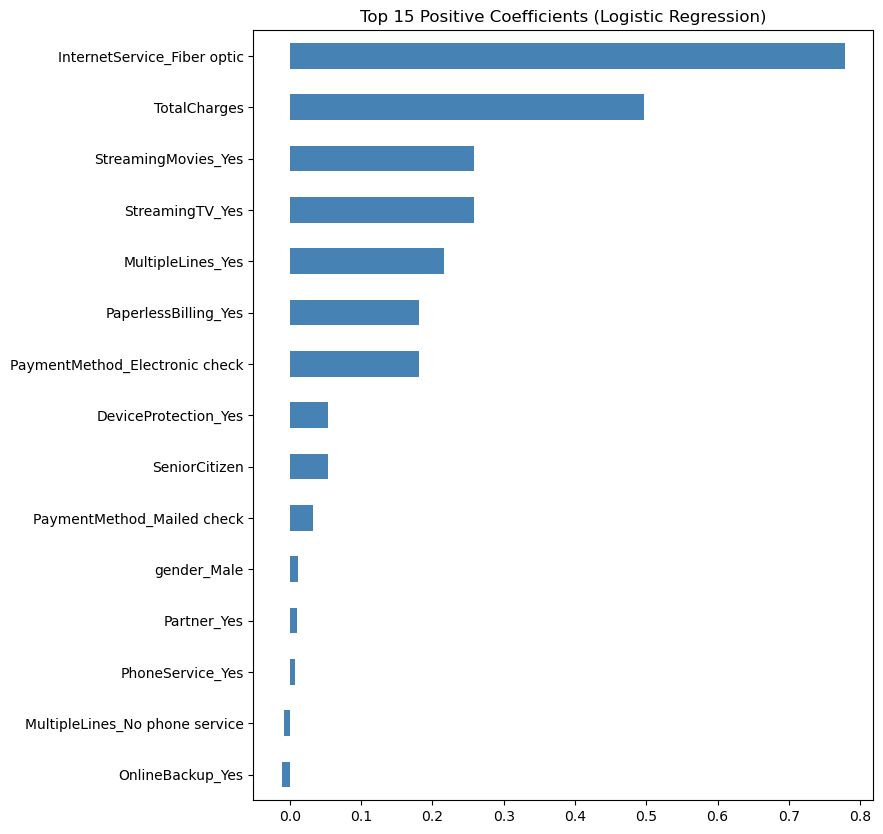

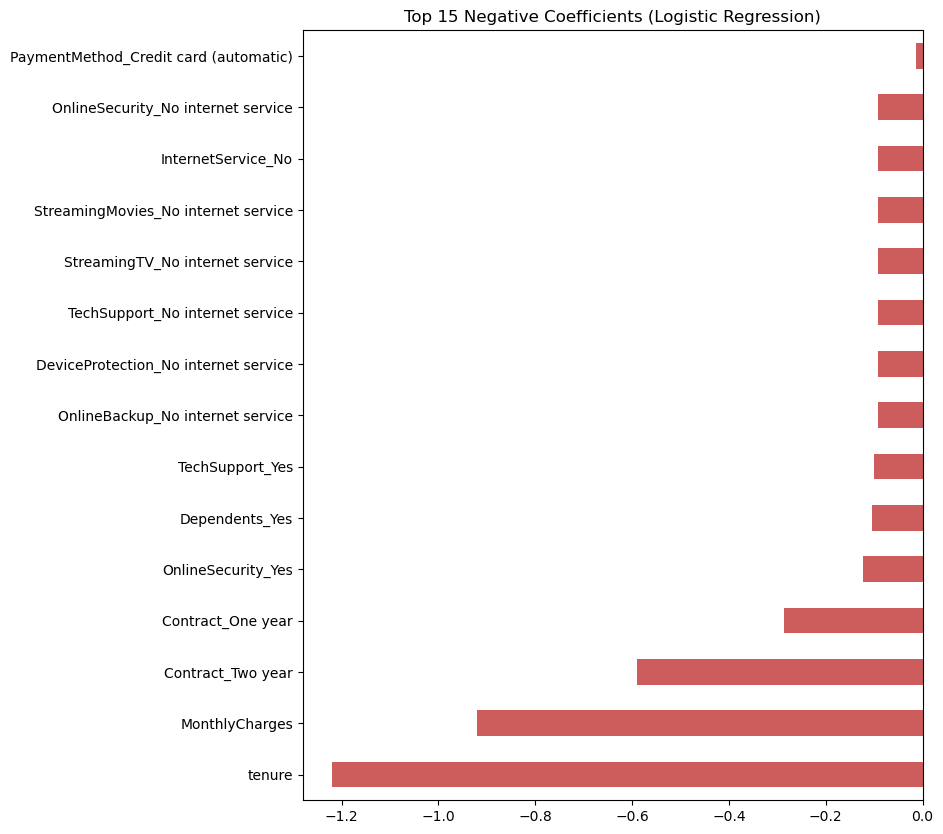

In [27]:
lr = models["Logistic Regression"]
coefs = pd.Series(lr.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8,10))
coefs.tail(15).plot(kind="barh", color="steelblue")
plt.title("Top 15 Positive Coefficients (Logistic Regression)")
plt.show()

plt.figure(figsize=(8,10))
coefs.head(15).plot(kind="barh", color="indianred")
plt.title("Top 15 Negative Coefficients (Logistic Regression)")
plt.show()

tenure                             0.181290
TotalCharges                       0.163687
MonthlyCharges                     0.120182
InternetService_Fiber optic        0.068193
Contract_Two year                  0.059945
PaymentMethod_Electronic check     0.059084
Contract_One year                  0.034928
OnlineSecurity_Yes                 0.034836
TechSupport_Yes                    0.024977
PaperlessBilling_Yes               0.022025
OnlineBackup_Yes                   0.016179
gender_Male                        0.015994
MultipleLines_Yes                  0.015677
TechSupport_No internet service    0.015313
Dependents_Yes                     0.014873
dtype: float64


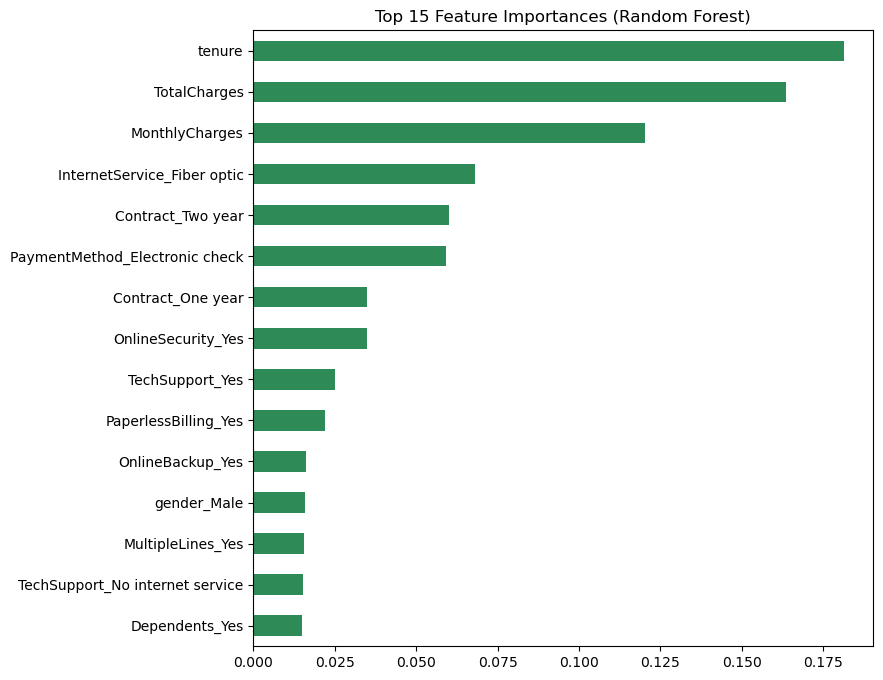

In [28]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
print(importances.head(15))

importances.head(15).plot(kind="barh", figsize=(8,8), color="seagreen")
plt.gca().invert_yaxis()
plt.title("Top 15 Feature Importances (Random Forest)")
plt.show()

<a id="part-15"></a>
# Feature Importance
## Most Important Variables
1. **Contract type** — month-to-month customers churn far more.
2. **tenure** — new customers at highest risk.
3. **TotalCharges / MonthlyCharges** — cost-sensitive customers churn more.
## Second-Most Important
4. **InternetService (Fiber optic)** — high churn segment.
5. **OnlineSecurity / TechSupport** — absence correlates with churn.
6. **PaymentMethod (electronic check)** — strong churn signal.
## Least Important
- **gender** — near zero importance.
- **PhoneService** — weak signal.
- **StreamingTV / StreamingMovies** — weak signal.
## Why These Variables Matter
- **Contract** captures commitment — no lock-in means easy exit.
- **tenure** reflects loyalty and switching cost.
- **Charges** reflect price sensitivity.
- **Service add-ons** increase stickiness — customers without them have less to lose.

# Business Recommendations
1. **Target month-to-month customers** with incentives to move to annual contracts (discounts, loyalty perks).
2. **Focus retention on first 12 months** — new customers churn most; improve onboarding.
3. **Review Fiber optic pricing/quality** — highest-churn segment.
4. **Bundle OnlineSecurity and TechSupport** — customers with these churn less.
5. **Promote automatic payment methods** — electronic-check users churn more.
6. **Deploy the model in CRM** — score customers monthly, trigger retention offers for high-risk ones.
7. **Monitor model performance quarterly** — retrain as behaviour shifts.

<a id="part-17"></a>
# Conclusion
| Item | Summary |
|------|---------|
| **Problem investigated** | Customer churn in telecommunications |
| **Dataset used** | Telco Customer Churn (7,043 rows, 21 features) |
| **Data preparation** | Cleaned blank `TotalCharges`, dropped `customerID`, one-hot encoded categoricals, scaled for LR/KNN, 80/20 stratified split |
| **Models developed** | Logistic Regression, Decision Tree, Random Forest, KNN |
| **Best-performing model** | Logistic Regression (ROC-AUC ≈ 0.84, F1 ≈ 0.60) |
| **Important predictors** | Contract type, tenure, TotalCharges, MonthlyCharges, InternetService, OnlineSecurity/TechSupport |
| **Limitations** | Class imbalance (~27% churn), single snapshot in time, no external economic features, no hyperparameter tuning in baseline, no cross-validation |

<a id="part-19"></a>
# References (IEEE Style)
[1] J. Hadden, A. Tiwari, R. Roy, and D. Ruta, "Computer assisted customer churn management: State-of-the-art and future trends," *Computers & Operations Research*, vol. 34, no. 10, pp. 2902–2917, 2007.
[2] B. Huang, M. T. Kechadi, and B. Buckley, "Customer churn prediction in telecommunications," *Expert Systems with Applications*, vol. 39, no. 1, pp. 1414–1425, 2012.
[3] S. A. Qureshi, A. S. Rehman, A. M. Qamar, A. Kamal, and A. Rehman, "Telecommunication subscribers' churn prediction model using machine learning," in *Proc. 8th Int. Conf. Digital Information Management*, 2013, pp. 131–136.
[4] K. Coussement and D. Van den Poel, "Churn prediction in subscription services: An application of support vector machines while comparing two parameter-selection techniques," *Expert Systems with Applications*, vol. 34, no. 1, pp. 313–327, 2008.
[5] F. Reichheld and W. E. Sasser, "Zero defections: Quality comes to services," *Harvard Business Review*, vol. 68, no. 5, pp. 105–111, 1990.
[6] S. Gupta and D. R. Lehmann, "Managing customers as investments: The strategic value of customers in the long run," *Journal of Marketing*, vol. 69, no. 1, pp. 141–142, 2005.
[7] IBM Cognos Analytics, "Telco Customer Churn Sample Data," IBM, 2019. [Online]. Available: https://www.ibm.com/analytics

In [29]:
import joblib

# Save the trained model, scaler, and feature columns for deployment
joblib.dump(models["Logistic Regression"], "logistic_regression_model.pkl")
joblib.dump(scaler, "scaler.pkl")
joblib.dump(X.columns.tolist(), "feature_columns.pkl")

print("Deployment files saved successfully!")

Deployment files saved successfully!
